# Phase 2 — One-Class Regime and Personalization Premium (RQ1)

## Decisions carried over from Phase 1

| Finding | Result |
|---|---|
| Device distinguishability 0.9805 (8.8x chance) | Personalization precondition satisfied |
| Supervised binary detection F1 = 0.9999 | **Ceiling effect** — the supervised regime is abandoned |
| Consecutive rows at 63% of independence | Temporal split is mandatory |
| Duplicate rows 18.6% | Effect will be measured |

This notebook works in the **one-class anomaly detection** regime: the model is calibrated only
on benign traffic and never sees an attack sample. This is both a realistic deployment scenario
and the setup that breaks the ceiling effect.

---

## We split personalization in two

The literature compares a "per-device model" with a "global model". But personalization
contains two separate components:

1. **Representation** — the normal-behavior pattern the model learns
2. **Threshold** — the anomaly-score value beyond which an alarm is raised

Building a global model and tuning the threshold per device is also a form of personalization, and is far
cheaper. If the two are not separated, the statement "personalization works" does not say which
component it belongs to.

### Configurations to compare

| Code | Model training | Threshold | What it tests |
|---|---|---|---|
| **G-G** | Benign data of all devices | Single global threshold | No personalization |
| **G-D** | Benign data of all devices | Per device | Threshold personalization only |
| **C-D** | Per device class | Per device | Class-level personalization |
| **R-D** | **Random groups** | Per device | **Grouping noise floor** |
| **D-D** | Per device | Per device | Full personalization |
| **D-D₂** | Per device, different seed | Per device | **Run noise floor** |

There are two noise floors and both are critical:

- **R-D** assigns devices to random groups. Group sizes are the same as in C-D but the grouping
  information is meaningless. C-D's advantage over R-D is the real contribution of class information.
- **D-D₂** is a repeat of D-D with a different seed. The difference between them is the fluctuation
  from running the same configuration twice. All premiums are compared against this floor.

## 0. Environment

In [1]:
import sys, os, glob, time, json, pickle, random, warnings
from collections import defaultdict

_PYLIBS = os.path.expanduser("~/work/pylibs")
if os.path.isdir(_PYLIBS) and _PYLIBS not in sys.path:
    sys.path.insert(0, _PYLIBS)

os.environ["OMP_NUM_THREADS"]      = "8"
os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["MKL_NUM_THREADS"]      = "8"
os.environ["CUDA_CACHE_PATH"]      = os.path.expanduser("~/work/.cuda_cache")
os.makedirs(os.environ["CUDA_CACHE_PATH"], exist_ok=True)

import ctypes
try:
    import nvidia
    libdirs = sorted(glob.glob(os.path.join(os.path.dirname(nvidia.__file__), "*", "lib")))
    os.environ["LD_LIBRARY_PATH"] = ":".join(libdirs) + ":" + os.environ.get("LD_LIBRARY_PATH", "")
    n = 0
    for d in libdirs:
        for so in sorted(glob.glob(os.path.join(d, "*.so*"))):
            try: ctypes.CDLL(so, mode=ctypes.RTLD_GLOBAL); n += 1
            except OSError: pass
    print(f"{n} CUDA libraries preloaded")
except ImportError:
    print("no nvidia packages - CPU")

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt; import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
matplotlib.rcParams["figure.dpi"] = 60
matplotlib.rcParams["savefig.dpi"] = 300
matplotlib.rcParams["savefig.bbox"] = "tight"

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

31 CUDA kutuphanesi on-yuklendi


I0000 00:00:1790342760.792056  867192 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790342760.817068  867192 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1790342761.292766  867192 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1790342761.468123  867192 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [2]:
# ============ SETTINGS ====================================================
KOK = os.path.expanduser("~/work/IoT_Botnet/veri/nbaiot")
OUT = os.path.expanduser("~/work/IoT_Botnet/faz2_ciktilar")
for s in ("figures", "tables"): os.makedirs(f"{OUT}/{s}", exist_ok=True)
CKPT = f"{OUT}/faz2_checkpoint.pkl"

SEED       = 42
SEED2      = 7          # second seed for the noise floor
EPOCHS     = 60
BATCH      = 256
PATIENCE   = 8
LR         = 1e-3
KOD_BOYUT  = 16         # autoencoder bottleneck size

KALIBRASYON = 0.60      # share of benign data used for training
ESIK_DILIM  = 0.10      # share used for threshold selection
TEST_DILIM  = 0.30      # share used for evaluation

HEDEF_FPR   = 0.01      # threshold is chosen for this false alarm rate
SALDIRI_TEST = 30_000   # attack samples used in evaluation per device+type
TEKILLESTIR = False     # whether to drop duplicate rows (effect is measured separately)

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    os.environ["PYTHONHASHSEED"] = str(s)

def savefig(ad):
    plt.savefig(f"{OUT}/figures/{ad}.png"); plt.show()

# Device classes (by manufacturer/type)
CIHAZ_SINIFI = {
    "Danmini_Doorbell": "kapi_zili",
    "Ennio_Doorbell": "kapi_zili",
    "Ecobee_Thermostat": "termostat",
    "Philips_B120N10_Baby_Monitor": "bebek_monitoru",
    "Provision_PT_737E_Security_Camera": "kamera",
    "Provision_PT_838_Security_Camera": "kamera",
    "Samsung_SNH_1011_N_Webcam": "webcam",
    "SimpleHome_XCS7_1002_WHT_Security_Camera": "kamera",
    "SimpleHome_XCS7_1003_WHT_Security_Camera": "kamera",
}
print("Output:", OUT)

Cikti: /home/jovyan/work/IoT_Botnet/faz2_ciktilar


## 1. Data loading

Benign traffic is loaded **in full** (needed for calibration). Attack traffic is sampled
per device+type for evaluation.

Row order is preserved — the temporal split relies on it.

In [3]:
def dosya_bilgisi(yol):
    p = os.path.relpath(yol, KOK).split(os.sep)
    if len(p) == 2:
        return p[0], "benign", "benign"
    return p[0], p[1].replace("_attacks", ""), os.path.splitext(p[-1])[0]

dosyalar = [f for f in sorted(glob.glob(f"{KOK}/**/*.csv", recursive=True))
            if "demonstrate" not in f]

t0 = time.time()
IYI, SALDIRI = {}, defaultdict(dict)
for f in dosyalar:
    cihaz, aile, tur = dosya_bilgisi(f)
    df = pd.read_csv(f, dtype="float32")
    if aile == "benign":
        IYI[cihaz] = df.to_numpy()
    else:
        A = df.to_numpy()
        if len(A) > SALDIRI_TEST:
            A = A[:SALDIRI_TEST]
        SALDIRI[cihaz][f"{aile}:{tur}"] = A

OZNITELIKLER = list(pd.read_csv(dosyalar[0], nrows=1).columns)
CIHAZLAR = sorted(IYI)
print(f"Loaded ({time.time()-t0:.0f} s)")
print(f"Devices: {len(CIHAZLAR)} | Features: {len(OZNITELIKLER)}")
for c in CIHAZLAR:
    print(f"  {c:<44} benign={len(IYI[c]):>7,}  attack_types={len(SALDIRI[c])}")

Yuklendi (28 s)
Cihaz: 9 | Oznitelik: 115
  Danmini_Doorbell                             iyi= 49,548  saldiri_turu=10
  Ecobee_Thermostat                            iyi= 13,113  saldiri_turu=10
  Ennio_Doorbell                               iyi= 39,100  saldiri_turu=5
  Philips_B120N10_Baby_Monitor                 iyi=175,240  saldiri_turu=10
  Provision_PT_737E_Security_Camera            iyi= 62,154  saldiri_turu=10
  Provision_PT_838_Security_Camera             iyi= 98,514  saldiri_turu=10
  Samsung_SNH_1011_N_Webcam                    iyi= 52,150  saldiri_turu=5
  SimpleHome_XCS7_1002_WHT_Security_Camera     iyi= 46,585  saldiri_turu=10
  SimpleHome_XCS7_1003_WHT_Security_Camera     iyi= 19,528  saldiri_turu=10


## 2. Duplicate row analysis

In [4]:
yin_rapor = []
for c in CIHAZLAR:
    A = IYI[c]
    tekil = np.unique(A, axis=0)
    yin_rapor.append({
        "cihaz": c, "toplam": len(A), "tekil": len(tekil),
        "yinelenen": len(A) - len(tekil),
        "yinelenme_%": round(100 * (len(A) - len(tekil)) / len(A), 2),
    })
yin_df = pd.DataFrame(yin_rapor)
yin_df.to_csv(f"{OUT}/tables/f2_tablo0_yinelenen.csv", index=False)
print(yin_df.to_string(index=False))
print(f"\nOverall duplicate rate: "
      f"{100*yin_df.yinelenen.sum()/yin_df.toplam.sum():.2f}%")
print("\nNOTE: Duplicate rows come from periods when the device is idle.")
print("If the same row appears in both calibration and test, it gives artificial success.")
print("The effect can be measured with TEKILLESTIR=True (needs a separate run).")

                                   cihaz  toplam  tekil  yinelenen  yinelenme_%
                        Danmini_Doorbell   49548  40395       9153        18.47
                       Ecobee_Thermostat   13113  13109          4         0.03
                          Ennio_Doorbell   39100  35407       3693         9.45
            Philips_B120N10_Baby_Monitor  175240 165141      10099         5.76
       Provision_PT_737E_Security_Camera   62154  55169       6985        11.24
        Provision_PT_838_Security_Camera   98514  93995       4519         4.59
               Samsung_SNH_1011_N_Webcam   52150  49559       2591         4.97
SimpleHome_XCS7_1002_WHT_Security_Camera   46585  42784       3801         8.16
SimpleHome_XCS7_1003_WHT_Security_Camera   19528  17935       1593         8.16

Genel yinelenme orani: 7.63%

NOT: Yinelenen satirlar cihazin sessiz oldugu donemlerden gelir.
Ayni satir hem kalibrasyonda hem testte olursa yapay basari verir.
TEKILLESTIR=True ile etkisi olculebil

## 3. Split protocol

For each device, benign data is split **temporally** into three:

- First 60% — autoencoder calibration
- Next 10% — threshold selection
- Last 30% — benign test (false alarm measurement)

All attack data is used on the test side; no model sees attacks.

In [5]:
def bol(A):
    n = len(A)
    i1 = int(KALIBRASYON * n)
    i2 = int((KALIBRASYON + ESIK_DILIM) * n)
    return A[:i1], A[i1:i2], A[i2:]

BOLUM = {}
for c in CIHAZLAR:
    A = np.unique(IYI[c], axis=0) if TEKILLESTIR else IYI[c]
    kal, esik, test = bol(A)
    BOLUM[c] = {"kalibrasyon": kal, "esik": esik, "test": test}

ozet = pd.DataFrame([{
    "cihaz": c,
    "kalibrasyon": len(BOLUM[c]["kalibrasyon"]),
    "esik": len(BOLUM[c]["esik"]),
    "iyi_test": len(BOLUM[c]["test"]),
    "saldiri_test": sum(len(v) for v in SALDIRI[c].values()),
} for c in CIHAZLAR])
ozet.to_csv(f"{OUT}/tables/f2_tablo1_bolme.csv", index=False)
print(ozet.to_string(index=False))

                                   cihaz  kalibrasyon  esik  iyi_test  saldiri_test
                        Danmini_Doorbell        29728  4955     14865        298917
                       Ecobee_Thermostat         7867  1312      3934        297494
                          Ennio_Doorbell        23460  3910     11730        147917
            Philips_B120N10_Baby_Monitor       105144 17523     52573        296208
       Provision_PT_737E_Security_Camera        37292  6215     18647        299297
        Provision_PT_838_Security_Camera        59108  9851     29555        297465
               Samsung_SNH_1011_N_Webcam        31290  5215     15645        146003
SimpleHome_XCS7_1002_WHT_Security_Camera        27951  4658     13976        296404
SimpleHome_XCS7_1003_WHT_Security_Camera        11716  1953      5859        295985


## 4. Autoencoder and evaluation

The model is trained only on benign data and learns to reproduce its own input.
Because attack traffic does not fit the normal pattern, reconstruction error rises.

The **threshold** is chosen from the benign threshold slice according to the target false alarm rate
(default 1%). This is the only operationally meaningful threshold choice — it rests on the definition
of an "acceptable false alarm" rather than an arbitrary percentile.

Reported metrics:
- **TPR@1%FPR** — detection rate at a 1% false alarm budget (main metric)
- **ROC-AUC**, **PR-AUC** — threshold-independent
- **Actual FPR** — whether the threshold held on the test set

In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score

def ae_kur(giris_boyut, tohum):
    set_seed(tohum)
    inp = layers.Input(shape=(giris_boyut,))
    x = layers.Dense(64, activation="relu")(inp)
    x = layers.Dense(32, activation="relu")(x)
    kod = layers.Dense(KOD_BOYUT, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(kod)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(giris_boyut, activation="linear")(x)
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="mse")
    return m


def olcekleyici(A):
    mu = A.mean(0); sd = A.std(0) + 1e-8
    return mu, sd


def ae_egit(kalibrasyon, tohum):
    mu, sd = olcekleyici(kalibrasyon)
    X = (kalibrasyon - mu) / sd
    X = np.clip(X, -20, 20).astype("float32")
    n_val = max(1, int(0.1 * len(X)))
    m = ae_kur(X.shape[1], tohum)
    m.fit(X[:-n_val], X[:-n_val],
          validation_data=(X[-n_val:], X[-n_val:]),
          epochs=EPOCHS, batch_size=BATCH, verbose=0,
          callbacks=[callbacks.EarlyStopping(monitor="val_loss",
                                             patience=PATIENCE,
                                             restore_best_weights=True)])
    return m, mu, sd


def hata(m, mu, sd, A):
    X = np.clip((A - mu) / sd, -20, 20).astype("float32")
    R = m.predict(X, batch_size=4096, verbose=0)
    return np.mean((X - R) ** 2, axis=1)


def degerlendir(iyi_hata, saldiri_hatalari, esik):
    """saldiri_hatalari: {tur: np.array}"""
    fpr = float((iyi_hata > esik).mean())
    tum_saldiri = np.concatenate(list(saldiri_hatalari.values()))
    tpr = float((tum_saldiri > esik).mean())
    y = np.r_[np.zeros(len(iyi_hata)), np.ones(len(tum_saldiri))]
    s = np.r_[iyi_hata, tum_saldiri]
    sonuc = {
        "TPR@esik": round(tpr, 4),
        "FPR_gercek": round(fpr, 4),
        "ROC_AUC": round(float(roc_auc_score(y, s)), 4),
        "PR_AUC": round(float(average_precision_score(y, s)), 4),
    }
    for tur, h in saldiri_hatalari.items():
        sonuc[f"TPR_{tur}"] = round(float((h > esik).mean()), 4)
    return sonuc

## 5. Configurations

Six configurations. Each determines which devices' benign data to train on and how the
threshold is chosen.

In [7]:
rs = np.random.RandomState(SEED)

# Random groups: mimic the class size distribution but carry no information
sinif_boyutlari = pd.Series(CIHAZ_SINIFI).value_counts().tolist()
karisik = list(rs.permutation(CIHAZLAR))
RASTGELE_GRUP, i = {}, 0
for g, b in enumerate(sinif_boyutlari):
    for c in karisik[i:i+b]:
        RASTGELE_GRUP[c] = f"rastgele_{g}"
    i += b

print("Device classes:")
for s in sorted(set(CIHAZ_SINIFI.values())):
    uyeler = [c for c in CIHAZLAR if CIHAZ_SINIFI[c] == s]
    print(f"  {s:<16} ({len(uyeler)}): {[u[:24] for u in uyeler]}")
print("\nRandom groups (noise floor):")
for s in sorted(set(RASTGELE_GRUP.values())):
    uyeler = [c for c in CIHAZLAR if RASTGELE_GRUP[c] == s]
    print(f"  {s:<16} ({len(uyeler)}): {[u[:24] for u in uyeler]}")

YAPILANDIRMALAR = {
    "G-G":  {"gruplama": "kuresel",  "esik": "kuresel", "tohum": SEED},
    "G-D":  {"gruplama": "kuresel",  "esik": "cihaz",   "tohum": SEED},
    "C-D":  {"gruplama": "sinif",    "esik": "cihaz",   "tohum": SEED},
    "R-D":  {"gruplama": "rastgele", "esik": "cihaz",   "tohum": SEED},
    "D-D":  {"gruplama": "cihaz",    "esik": "cihaz",   "tohum": SEED},
    "D-D2": {"gruplama": "cihaz",    "esik": "cihaz",   "tohum": SEED2},
}

def grup_uyeleri(gruplama, cihaz):
    if gruplama == "cihaz":    return [cihaz]
    if gruplama == "kuresel":  return CIHAZLAR
    if gruplama == "sinif":
        return [c for c in CIHAZLAR if CIHAZ_SINIFI[c] == CIHAZ_SINIFI[cihaz]]
    if gruplama == "rastgele":
        return [c for c in CIHAZLAR if RASTGELE_GRUP[c] == RASTGELE_GRUP[cihaz]]
    raise ValueError(gruplama)

Cihaz siniflari:
  bebek_monitoru   (1): ['Philips_B120N10_Baby_Mon']
  kamera           (4): ['Provision_PT_737E_Securi', 'Provision_PT_838_Securit', 'SimpleHome_XCS7_1002_WHT', 'SimpleHome_XCS7_1003_WHT']
  kapi_zili        (2): ['Danmini_Doorbell', 'Ennio_Doorbell']
  termostat        (1): ['Ecobee_Thermostat']
  webcam           (1): ['Samsung_SNH_1011_N_Webca']

Rastgele gruplar (gurultu tabani):
  rastgele_0       (4): ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Provision_PT_838_Securit', 'SimpleHome_XCS7_1002_WHT']
  rastgele_1       (2): ['Ennio_Doorbell', 'SimpleHome_XCS7_1003_WHT']
  rastgele_2       (1): ['Provision_PT_737E_Securi']
  rastgele_3       (1): ['Philips_B120N10_Baby_Mon']
  rastgele_4       (1): ['Samsung_SNH_1011_N_Webca']


## 6. Main loop

In [8]:
if os.path.exists(CKPT):
    with open(CKPT, "rb") as f: DURUM = pickle.load(f)
    print(f"Previous checkpoint: {len(DURUM['sonuclar'])} evaluations")
else:
    DURUM = {"sonuclar": [], "hatalar": {}}
    print("New run")

tamam = {(r["yapilandirma"], r["cihaz"]) for r in DURUM["sonuclar"]}
t_bas = time.time()

for yad, ycfg in YAPILANDIRMALAR.items():
    print(f"\n{'='*66}\n  {yad}  (gruplama={ycfg['gruplama']}, esik={ycfg['esik']})\n{'='*66}")

    # Models for the same group are trained once and used for all members
    egitilmis = {}

    for cihaz in CIHAZLAR:
        if (yad, cihaz) in tamam:
            print(f"  {cihaz[:40]:<42} skipped"); continue

        uyeler = grup_uyeleri(ycfg["gruplama"], cihaz)
        anahtar = tuple(sorted(uyeler))

        if anahtar not in egitilmis:
            kal = np.concatenate([BOLUM[c]["kalibrasyon"] for c in uyeler])
            m, mu, sd = ae_egit(kal, ycfg["tohum"])
            egitilmis[anahtar] = (m, mu, sd, uyeler)
        m, mu, sd, uyeler = egitilmis[anahtar]

        # --- threshold selection ---
        if ycfg["esik"] == "cihaz":
            esik_veri = BOLUM[cihaz]["esik"]
        else:   # global threshold: threshold slices of all devices together
            esik_veri = np.concatenate([BOLUM[c]["esik"] for c in CIHAZLAR])
        esik = float(np.quantile(hata(m, mu, sd, esik_veri), 1 - HEDEF_FPR))

        # --- evaluation ---
        iyi_h = hata(m, mu, sd, BOLUM[cihaz]["test"])
        sal_h = {tur: hata(m, mu, sd, A) for tur, A in SALDIRI[cihaz].items()}
        skor = degerlendir(iyi_h, sal_h, esik)

        kayit = {"yapilandirma": yad, "cihaz": cihaz,
                 "grup_boyutu": len(uyeler), "esik": esik, **skor}
        DURUM["sonuclar"].append(kayit)
        DURUM["hatalar"][(yad, cihaz)] = {
            "iyi": iyi_h.astype("float32"),
            "saldiri": {k: v.astype("float32") for k, v in sal_h.items()},
            "esik": esik,
        }
        print(f"  {cihaz[:40]:<42} TPR={skor['TPR@esik']:.4f} "
              f"FPR={skor['FPR_gercek']:.4f} AUC={skor['ROC_AUC']:.4f}")

    for m, *_ in egitilmis.values(): del m
    tf.keras.backend.clear_session()
    with open(CKPT, "wb") as f: pickle.dump(DURUM, f)

print(f"\nTotal time: {(time.time()-t_bas)/60:.1f} minutes")
df = pd.DataFrame(DURUM["sonuclar"])
df.to_csv(f"{OUT}/tables/f2_ham_sonuclar.csv", index=False)
print(df.groupby("yapilandirma")[["TPR@esik","FPR_gercek","ROC_AUC","PR_AUC"]]
        .mean().round(4).to_string())

Yeni kosu

  G-G  (gruplama=kuresel, esik=kuresel)


W0000 00:00:1790342790.688743  867192 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1790342790.767820  867192 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4006 MB memory:  -> device: 0, name: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition, pci bus id: 0000:02:00.0, compute capability: 12.0a
I0000 00:00:1790342791.763271  867374 service.cc:153] XLA service 0x7e4b18033730 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790342791.763297  867374 service.cc:161]   StreamExecutor [0]: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1790342791.780954  867374 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var 

  Danmini_Doorbell                           TPR=0.7991 FPR=0.0000 AUC=0.9977
  Ecobee_Thermostat                          TPR=0.7980 FPR=0.0046 AUC=0.9365


I0000 00:00:1790342882.887077  875603 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1790342883.643313  867374 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790342884.678657  875898 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 12 bytes spill stores, 12 bytes spill loads



  Ennio_Doorbell                             TPR=0.5942 FPR=0.0003 AUC=0.9878


...

  Samsung_SNH_1011_N_Webcam                  TPR=0.5890 FPR=0.0029 AUC=0.9855


I0000 00:00:1790343583.980595  867368 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1571525__.9
I0000 00:00:1790343585.108900  867368 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1571525__.9


  SimpleHome_XCS7_1002_WHT_Security_Camera   TPR=0.7973 FPR=0.0077 AUC=0.9917


I0000 00:00:1790343598.180514  867371 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1597453__.9
I0000 00:00:1790343599.134351  867374 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1597453__.9


  SimpleHome_XCS7_1003_WHT_Security_Camera   TPR=0.7973 FPR=0.0009 AUC=0.9983

Toplam sure: 13.7 dakika
              TPR@esik  FPR_gercek  ROC_AUC  PR_AUC
yapilandirma                                       
C-D             0.7523      0.0099   0.9876  0.9992
D-D             0.7747      0.0090   0.9932  0.9995
D-D2            0.7747      0.0097   0.9939  0.9995
G-D             0.7522      0.0071   0.9781  0.9986
G-G             0.7521      0.0045   0.9781  0.9986
R-D             0.7746      0.0099   0.9930  0.9995


## 7. RQ1 — Personalization premium

Each configuration's gap from full personalization (D-D) is read together with the two noise floors:

- **Run floor** = |D-D − D-D₂|. The difference between two seeds of the same configuration.
- **Grouping floor** = C-D − R-D. Class information's advantage over random grouping.

A premium smaller than the run floor is considered **unmeasurable**.

In [9]:
from scipy import stats

df = pd.DataFrame(DURUM["sonuclar"])
ANA = "TPR@esik"

pv = df.pivot(index="cihaz", columns="yapilandirma", values=ANA)
pv = pv[[k for k in YAPILANDIRMALAR if k in pv.columns]]
pv.to_csv(f"{OUT}/tables/f2_tablo2_cihaz_bazli_tpr.csv")
print(f"{ANA} — device x configuration\n")
print((pv * 100).round(2).to_string())

# --- noise floors ---
kosu_tabani = float((pv["D-D"] - pv["D-D2"]).abs().mean()) if "D-D2" in pv else np.nan
print(f"\nRUN NOISE FLOOR  mean |D-D - D-D2| = {100*kosu_tabani:.3f} percentage points")

satir = []
for y in pv.columns:
    if y == "D-D": continue
    d = (pv["D-D"] - pv[y]).dropna()
    t, p = stats.ttest_rel(pv.loc[d.index, "D-D"], pv.loc[d.index, y])
    try:    _, pw = stats.wilcoxon(pv.loc[d.index, "D-D"], pv.loc[d.index, y])
    except Exception: pw = np.nan
    satir.append({
        "Karsilastirma": f"D-D vs {y}",
        "Prim (yuzde puan)": round(100 * d.mean(), 3),
        "Std": round(100 * d.std(), 3),
        "t": round(t, 3), "p": round(p, 4),
        "p_wilcoxon": round(pw, 4) if pw == pw else "-",
        "D-D kazandi": int((d > 0).sum()),
        "n": len(d),
        "Gurultu tabaninin kaci": (round(abs(d.mean()) / kosu_tabani, 2)
                                   if kosu_tabani and kosu_tabani > 0 else "-"),
    })
prim = pd.DataFrame(satir)
prim.to_csv(f"{OUT}/tables/f2_tablo3_kisisellestirme_primi.csv", index=False)
print("\n" + prim.to_string(index=False))

TPR@esik — cihaz x yapilandirma

yapilandirma                                G-G    G-D    C-D     R-D     D-D    D-D2
cihaz                                                                                
Danmini_Doorbell                          79.91  79.94  79.94  100.00  100.00  100.00
Ecobee_Thermostat                         79.80  79.81  79.85   79.82   79.85   79.85
Ennio_Doorbell                            59.42  59.44  59.46   59.46   59.47   59.47
Philips_B120N10_Baby_Monitor              79.72  79.72  79.74   79.74   79.74   79.74
Provision_PT_737E_Security_Camera         79.93  79.94  79.94   79.95   79.95   79.95
Provision_PT_838_Security_Camera          79.81  79.82  79.82   79.82   79.83   79.83
Samsung_SNH_1011_N_Webcam                 58.90  58.89  58.89   58.89   58.89   58.90
SimpleHome_XCS7_1002_WHT_Security_Camera  79.72  79.72  79.73   79.73   79.73   79.73
SimpleHome_XCS7_1003_WHT_Security_Camera  79.69  79.69  79.69   79.72   79.73   79.73

KOSU GURULTU TABANI 

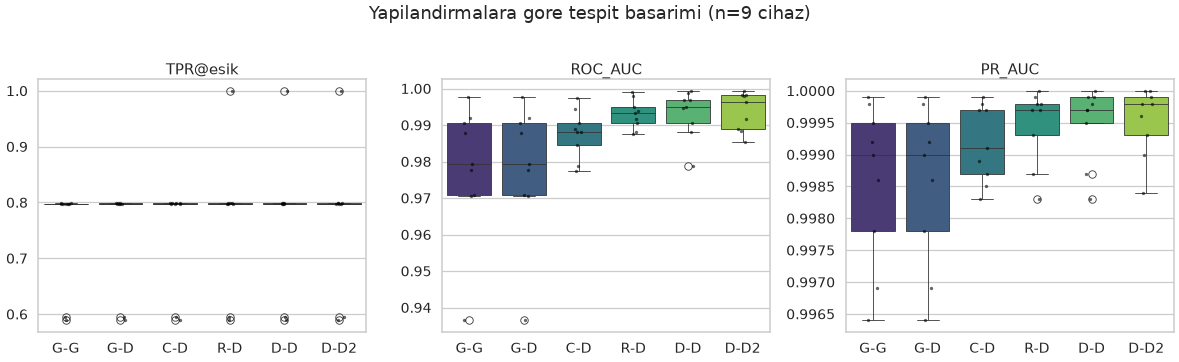

In [10]:
# ---- Figure: distribution by configuration -------------------------------
uzun = df.melt(id_vars=["yapilandirma", "cihaz"],
               value_vars=["TPR@esik", "ROC_AUC", "PR_AUC"],
               var_name="metrik", value_name="deger")
sira = [k for k in YAPILANDIRMALAR if k in df.yapilandirma.unique()]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, met in zip(axes, ["TPR@esik", "ROC_AUC", "PR_AUC"]):
    alt = uzun[uzun.metrik == met]
    sns.boxplot(data=alt, x="yapilandirma", y="deger", order=sira,
                hue="yapilandirma", palette="viridis", legend=False, ax=ax)
    sns.stripplot(data=alt, x="yapilandirma", y="deger", order=sira,
                  color="black", size=4, alpha=0.6, ax=ax)
    ax.set_title(met); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Yapilandirmalara gore tespit basarimi (n=9 cihaz)", y=1.02)
plt.tight_layout(); savefig("f2_fig01_yapilandirma_dagilimi")

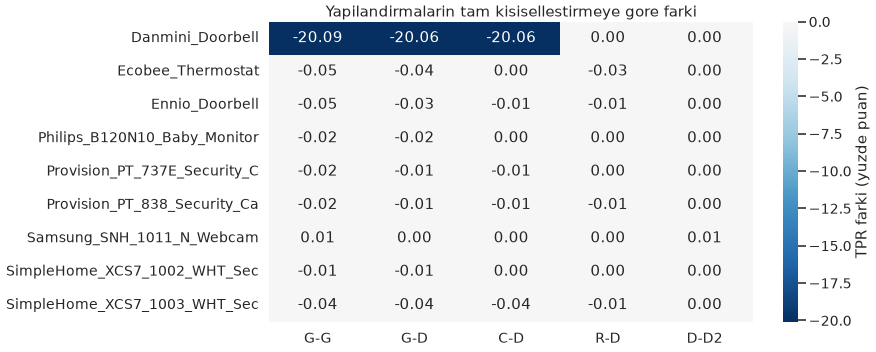

Referans: kosu gurultu tabani 0.001 yuzde puan.
Bu degerin altindaki farklar olculemez sayilir.


In [11]:
# ---- Figure: per-device premium (difference from D-D) -------------------------
fark = pv.sub(pv["D-D"], axis=0).drop(columns=["D-D"]) * 100
plt.figure(figsize=(13, 6.5))
sns.heatmap(fark, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "TPR farki (yuzde puan)"},
            yticklabels=[c[:28] for c in fark.index])
plt.title("Yapilandirmalarin tam kisisellestirmeye gore farki")
plt.xlabel(""); plt.ylabel("")
savefig("f2_fig02_cihaz_bazli_prim")

if kosu_tabani == kosu_tabani:
    print(f"Reference: run noise floor {100*kosu_tabani:.3f} percentage points.")
    print("Differences below this value are considered unmeasurable.")

## 8. Attack family and type breakdown

yapilandirma              D-D     G-D     G-G
aile   tur                                   
gafgyt gafgyt:combo    0.9999  0.9997  0.9997
       gafgyt:junk     0.9999  0.9997  0.9996
       gafgyt:scan     0.9998  0.9996  0.9996
       gafgyt:tcp      0.1119  0.0006  0.0003
       gafgyt:udp      0.1115  0.0002  0.0000
mirai  mirai:ack       0.9999  0.9999  0.9999
       mirai:scan      0.9994  0.9991  0.9990
       mirai:syn       0.9999  0.9997  0.9996
       mirai:udp       0.9998  0.9997  0.9997
       mirai:udpplain  1.0000  0.9999  1.0000


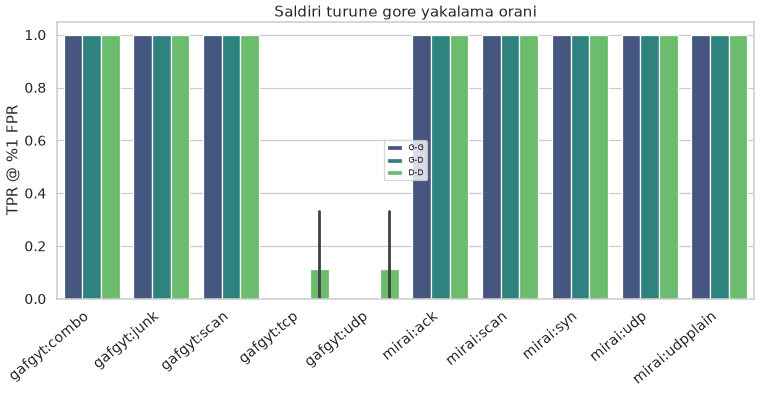


En zor yakalanan 5 saldiri turu (D-D):
  0.1115  gafgyt:udp
  0.1119  gafgyt:tcp
  0.9994  mirai:scan
  0.9998  gafgyt:scan
  0.9998  mirai:udp


In [12]:
tur_sut = [c for c in df.columns if c.startswith("TPR_")]
tur_df = (df[df.yapilandirma.isin(["D-D", "G-G", "G-D"])]
          .melt(id_vars=["yapilandirma", "cihaz"], value_vars=tur_sut,
                var_name="tur", value_name="TPR").dropna())
tur_df["tur"] = tur_df.tur.str.replace("TPR_", "", regex=False)
tur_df["aile"] = tur_df.tur.str.split(":").str[0]

ozet_tur = (tur_df.groupby(["yapilandirma", "aile", "tur"]).TPR.mean()
            .unstack(0).round(4))
ozet_tur.to_csv(f"{OUT}/tables/f2_tablo4_saldiri_turu.csv")
print(ozet_tur.to_string())

plt.figure(figsize=(15, 6))
sns.barplot(data=tur_df, x="tur", y="TPR", hue="yapilandirma", palette="viridis")
plt.xticks(rotation=40, ha="right"); plt.xlabel(""); plt.ylabel("TPR @ %1 FPR")
plt.title("Saldiri turune gore yakalama orani")
plt.legend(fontsize=9)
savefig("f2_fig03_saldiri_turu")

print("\n5 hardest-to-detect attack types (D-D):")
dd = tur_df[tur_df.yapilandirma == "D-D"].groupby("tur").TPR.mean().sort_values()
for k, v in dd.head(5).items(): print(f"  {v:.4f}  {k}")

## 9. Ceiling effect check

In [13]:
print("In Phase 1, supervised binary detection F1 was 0.9999 (ceiling).")
print("In the one-class regime:\n")
dd = df[df.yapilandirma == "D-D"]
print(f"  TPR@%1FPR : {dd['TPR@esik'].mean():.4f}  "
      f"(min {dd['TPR@esik'].min():.4f}, max {dd['TPR@esik'].max():.4f})")
print(f"  ROC-AUC   : {dd.ROC_AUC.mean():.4f}")
print(f"  PR-AUC    : {dd.PR_AUC.mean():.4f}")
print(f"  Actual FPR: {dd.FPR_gercek.mean():.4f}  (hedef {HEDEF_FPR})")

if dd["TPR@esik"].mean() > 0.99:
    print("\n  >> CEILING PERSISTS. Conditions must be made even harder:")
    print("     small calibration window (RQ2), unseen attack (RQ3),")
    print("     cross-device transfer (RQ4). Phase 3 covers these.")
elif dd["TPR@esik"].mean() > 0.90:
    print("\n  >> Ceiling broken but performance is high. Differences should be measurable.")
else:
    print("\n  >> The task is hard. Configuration differences should be clearly visible.")

print(f"\nIf the actual FPR deviates from the target, threshold generalization is weak.")
print(f"Deviation: {abs(dd.FPR_gercek.mean()-HEDEF_FPR):.4f}")

Faz 1'de denetimli ikili tespit F1 = 0.9999 (tavan) idi.
Tek sinifli rejimde:

  TPR@%1FPR : 0.7747  (min 0.5889, max 1.0000)
  ROC-AUC   : 0.9932
  PR-AUC    : 0.9995
  Gercek FPR: 0.0090  (hedef 0.01)

  >> Gorev zorlu. Yapilandirma farklari net gorunmeli.

Gercek FPR hedeften sapiyorsa esik genellemesi zayif demektir.
Sapma: 0.0010


## 10. Summary and export

In [14]:
ozet_json = {
    "rejim": "tek sinifli anomali tespiti",
    "ana_metrik": ANA,
    "hedef_fpr": HEDEF_FPR,
    "tekillestirme": TEKILLESTIR,
    "kosu_gurultu_tabani_yuzde_puan": round(100 * float(kosu_tabani), 4),
    "yapilandirma_ortalamalari": {
        y: round(float(pv[y].mean()), 4) for y in pv.columns
    },
    "primler": prim.to_dict("records"),
}
with open(f"{OUT}/tables/f2_ozet.json", "w") as fh:
    json.dump(ozet_json, fh, indent=2, ensure_ascii=False, default=str)
print(json.dumps(ozet_json, indent=2, ensure_ascii=False, default=str))

import shutil
ars = shutil.make_archive(os.path.expanduser("~/work/IoT_Botnet/faz2_ciktilar"),
                          "zip", OUT)
print("\nArchive:", ars, f"({os.path.getsize(ars)/1e6:.1f} MB)")

{
  "rejim": "tek sinifli anomali tespiti",
  "ana_metrik": "TPR@esik",
  "hedef_fpr": 0.01,
  "tekillestirme": false,
  "kosu_gurultu_tabani_yuzde_puan": 0.0011,
  "yapilandirma_ortalamalari": {
    "G-G": 0.7521,
    "G-D": 0.7522,
    "C-D": 0.7523,
    "R-D": 0.7746,
    "D-D": 0.7747,
    "D-D2": 0.7747
  },
  "primler": [
    {
      "Karsilastirma": "D-D vs G-G",
      "Prim (yuzde puan)": 2.254,
      "Std": 6.688,
      "t": 1.011,
      "p": 0.3415,
      "p_wilcoxon": 0.0117,
      "D-D kazandi": 8,
      "n": 9,
      "Gurultu tabaninin kaci": 2029.0
    },
    {
      "Karsilastirma": "D-D vs G-D",
      "Prim (yuzde puan)": 2.247,
      "Std": 6.68,
      "t": 1.009,
      "p": 0.3425,
      "p_wilcoxon": 0.0078,
      "D-D kazandi": 8,
      "n": 9,
      "Gurultu tabaninin kaci": 2022.0
    },
    {
      "Karsilastirma": "D-D vs C-D",
      "Prim (yuzde puan)": 2.237,
      "Std": 6.684,
      "t": 1.004,
      "p": 0.3448,
      "p_wilcoxon": 0.0625,
      "D-D kazand

---

## Post-run checklist

1. **Is the actual FPR close to the target?** (around 1%) If not, threshold generalization is weak and the threshold slice
   should be enlarged.
2. **Is the gap between D-D and D-D₂ small?** This is the run noise floor; if large, training
   is unstable and epochs or early stopping should be adjusted.
3. **How large is the gap between G-G and G-D?** This is the contribution of threshold personalization alone.
4. **How large is the gap between C-D and R-D?** This is the real contribution of class information.
5. **Is TPR still above 0.99?** If so, the hardened conditions in Phase 3 are essential.

Once these five are answered, RQ1 is closed.